Загружено нетоксичных оксидов: 23077 | Файл: ..\data\oxides_features_full.csv

=== Сравнение ранжирования моделей (5-fold GroupKFold, база FM+FiM = 45.99%) ===
             Модель         ROC-AUC          PR-AUC              F1  P@50 (%)  EF@50  P@100 (%)  EF@100  P@500 (%)  EF@500  P@1000 (%)  EF@1000  P@2000 (%)  EF@2000  P@5000 (%)  EF@5000
Logistic Regression 0.8905 ± 0.0060 0.8567 ± 0.0169 0.8022 ± 0.0070      86.0   1.87       92.0    2.00       94.0    2.04        93.5     2.03        93.6     2.04       89.98     1.96
      Random Forest 0.9508 ± 0.0038 0.9343 ± 0.0066 0.8811 ± 0.0091     100.0   2.17      100.0    2.17       99.2    2.16        98.7     2.15        98.5     2.14       95.94     2.09

=== Проверка эталонных материалов (OOF, скрытые chemsys: RF vs LR) ===
 rank  top_pct  rank_lr material_id   formula chemsys spacegroup_symbol ordering  total_magnetization  energy_above_hull  oof_prob  oof_prob_lr
  552     2.39      293   mp-697842 Mn(FeO2)2 Fe-Mn-O             

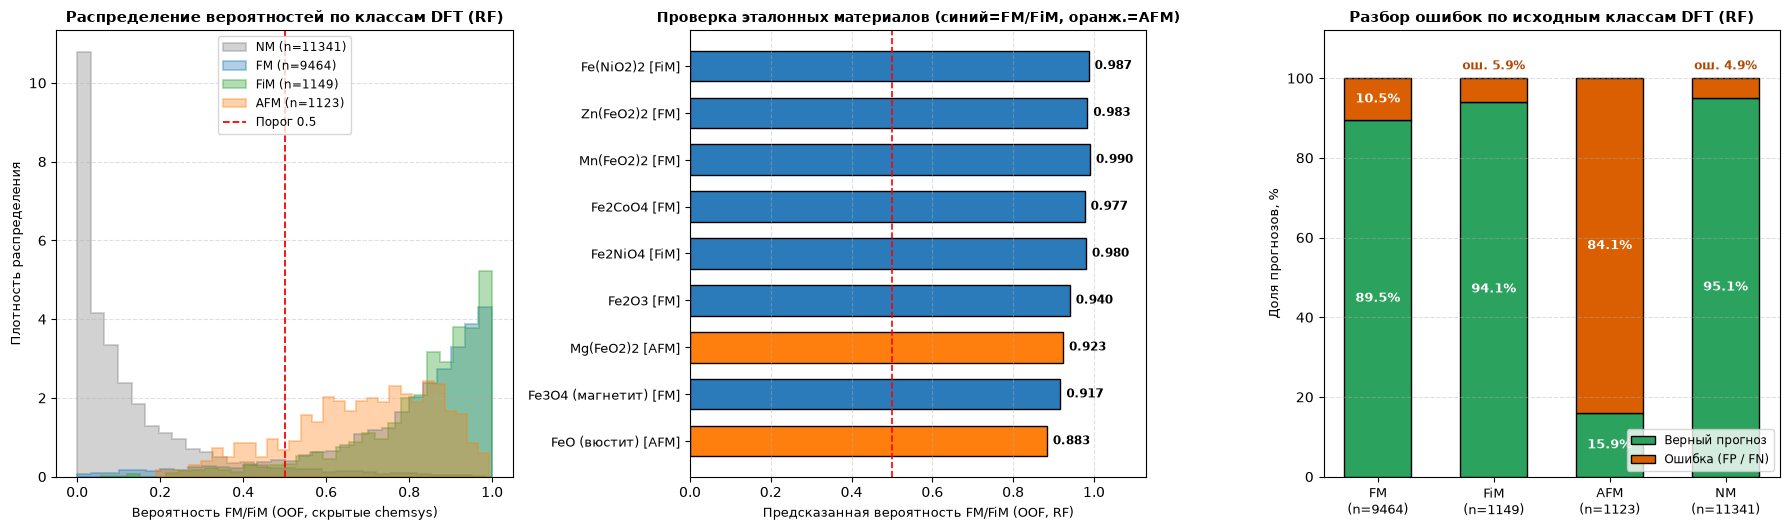

График сохранён: ..\figures\ranking_and_errors_report.png
Модели сохранены в ..\models/: rf_magnetic_oxides_v1.joblib и lr_magnetic_oxides_v1.joblib


In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score
)

# ------------------------------------------------------------------
# 1. Настройка путей (работает и из notebooks/, и из корня проекта)
# ------------------------------------------------------------------
ROOT = Path("..") if Path("../data/oxides_features_full.csv").exists() else Path(".")
DATA_PATH = ROOT / "data" / "oxides_features_full.csv"
if not DATA_PATH.exists():
    DATA_PATH = Path("oxides_features_full.csv")

RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"
MODELS_DIR = ROOT / "models"
for d in (RESULTS_DIR, FIGURES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f"Загружено нетоксичных оксидов: {len(df)} | Файл: {DATA_PATH}")

# ------------------------------------------------------------------
# 2. Матрица признаков (полный набор после проверки утечек через SG)
# ------------------------------------------------------------------
magpie_cols = [c for c in df.columns if c.startswith("MagpieData") and df[c].nunique() > 1]
struct_no_sym_cols = [
    "r_cation_mean", "r_cation_std", "r_cation_min", "r_cation_max",
    "r_cation_O_ratio", "octahedral_factor", "tolerance_factor", "n_cation_types",
    "cn_cation_O_mean", "cn_cation_O_std", "cn_cation_O_min", "cn_cation_O_max",
    "dist_MO_mean", "dist_MO_min", "dist_MM_min",
    "density", "volume_per_atom"
]
cs_dummies = pd.get_dummies(df["crystal_system"], prefix="cs", dtype=float)
X_full = pd.concat([df[magpie_cols + struct_no_sym_cols], df[["spacegroup_number"]], cs_dummies], axis=1)
feature_cols = list(X_full.columns)

# Целевая переменная: расчётные DFT-метки Materials Project (FM+FiM vs AFM+NM)
y = df["target_ferro"].values
groups = df["chemsys"].values

def build_lr_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ])

def build_rf_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

# ------------------------------------------------------------------
# 3. 5-fold GroupKFold по chemsys для обеих моделей (LR и RF)
# ------------------------------------------------------------------
gkf = GroupKFold(n_splits=5)
k_list = [50, 100, 500, 1000, 2000, 5000]
base_rate = y.mean()

model_builders = {
    "Logistic Regression": build_lr_pipeline,
    "Random Forest": build_rf_pipeline,
}

oof_dict = {}
comparison_rows = []

for name, builder in model_builders.items():
    oof = np.zeros(len(df))
    aucs, prs, f1s = [], [], []
    
    for tr, te in gkf.split(X_full, y, groups=groups):
        pipe = builder()
        pipe.fit(X_full.iloc[tr], y[tr])
        proba = pipe.predict_proba(X_full.iloc[te])[:, 1]
        oof[te] = proba
        aucs.append(roc_auc_score(y[te], proba))
        prs.append(average_precision_score(y[te], proba))
        f1s.append(f1_score(y[te], (proba >= 0.5).astype(int)))
        
    oof_dict[name] = oof
    
    # Сортировка по вероятности (убывание), при равенстве — по E_hull (возрастание)
    order_idx = np.lexsort((df["energy_above_hull"].values, -oof))
    y_sorted = y[order_idx]
    
    row = {
        "Модель": name,
        "ROC-AUC": f"{np.mean(aucs):.4f} ± {np.std(aucs):.4f}",
        "PR-AUC": f"{np.mean(prs):.4f} ± {np.std(prs):.4f}",
        "F1": f"{np.mean(f1s):.4f} ± {np.std(f1s):.4f}",
    }
    for k in k_list:
        p_k = y_sorted[:k].mean()
        row[f"P@{k} (%)"] = round(p_k * 100, 2)
        row[f"EF@{k}"] = round(p_k / base_rate, 2)
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
print(f"\n=== Сравнение ранжирования моделей (5-fold GroupKFold, база FM+FiM = {base_rate*100:.2f}%) ===")
print(comparison_df.to_string(index=False))
comparison_df.to_csv(RESULTS_DIR / "model_ranking_comparison.csv", index=False)

# ------------------------------------------------------------------
# 4. Ранжирование по лучшей модели (RF) + сравнение эталонов (RF vs LR)
# ------------------------------------------------------------------
df["oof_prob_lr"] = oof_dict["Logistic Regression"]
df["oof_prob"] = oof_dict["Random Forest"]
df["oof_pred"] = (df["oof_prob"] >= 0.5).astype(int)
df["error_type"] = np.where((df["target_ferro"] == 1) & (df["oof_pred"] == 1), "TP",
                   np.where((df["target_ferro"] == 0) & (df["oof_pred"] == 0), "TN",
                   np.where((df["target_ferro"] == 0) & (df["oof_pred"] == 1), "FP", "FN")))

# Считаем ранги для обеих моделей
df = df.sort_values(["oof_prob_lr", "energy_above_hull"], ascending=[False, True]).reset_index(drop=True)
df["rank_lr"] = np.arange(1, len(df) + 1)

df_ranked = df.sort_values(["oof_prob", "energy_above_hull"], ascending=[False, True]).reset_index(drop=True)
df_ranked["rank"] = np.arange(1, len(df_ranked) + 1)
df_ranked["top_pct"] = (df_ranked["rank"] / len(df_ranked) * 100).round(2)

# Эталонные материалы (магнетит, феррошпинели, вюстит)
ref_ids = [
    "mp-640147", "mp-1388646", "mp-697842", "mp-765860",
    "mp-22684", "mp-565814", "mp-608016", "mp-19306", "mp-1274279"
]
ref_cols = [
    "rank", "top_pct", "rank_lr", "material_id", "formula", "chemsys",
    "spacegroup_symbol", "ordering", "total_magnetization",
    "energy_above_hull", "oof_prob", "oof_prob_lr"
]
ref_table = df_ranked[df_ranked["material_id"].isin(ref_ids)][ref_cols]
print("\n=== Проверка эталонных материалов (OOF, скрытые chemsys: RF vs LR) ===")
print(ref_table.to_string(index=False))

# Топ-50 стабильных (E_hull = 0) нетоксичных кандидатов из разных chemsys
cand_cols = [
    "rank", "top_pct", "material_id", "formula", "chemsys",
    "spacegroup_symbol", "ordering", "total_magnetization",
    "energy_above_hull", "oof_prob"
]
top50_stable = (
    df_ranked[df_ranked["is_stable"] == True]
    .drop_duplicates(subset=["chemsys"])
    .head(50)[cand_cols]
)
print("\n=== Топ-10 стабильных (E_hull = 0) нетоксичных кандидатов (RF) ===")
print(top50_stable.head(10).to_string(index=False))

# ------------------------------------------------------------------
# 5. Разбор ошибок Random Forest и сохранение таблиц в results/
# ------------------------------------------------------------------
print("\n=== Разбор ошибок Random Forest по исходным классам DFT ===")
print(pd.crosstab(df_ranked["ordering"], df_ranked["error_type"], margins=True))
print(f"Precision = {precision_score(df_ranked['target_ferro'], df_ranked['oof_pred']):.4f} | "
      f"Recall = {recall_score(df_ranked['target_ferro'], df_ranked['oof_pred']):.4f}")

top_fp_nm = df_ranked[(df_ranked["error_type"] == "FP") & (df_ranked["ordering"] == "NM")][cand_cols].head(20)
top_fp_afm = df_ranked[(df_ranked["error_type"] == "FP") & (df_ranked["ordering"] == "AFM")][cand_cols].head(20)
top_fn = df_ranked[df_ranked["error_type"] == "FN"].sort_values("oof_prob", ascending=True)[cand_cols].head(20)

ref_table.to_csv(RESULTS_DIR / "reference_materials_check.csv", index=False)
top50_stable.to_csv(RESULTS_DIR / "top50_stable_candidates.csv", index=False)
pd.concat([
    top_fp_nm.assign(error_group="FP_actual_NM"),
    top_fp_afm.assign(error_group="FP_actual_AFM"),
    top_fn.assign(error_group="FN_actual_FM_FiM")
]).to_csv(RESULTS_DIR / "error_analysis_examples.csv", index=False)
print(f"\nТаблицы сохранены в {RESULTS_DIR}/")

# ------------------------------------------------------------------
# 6. Сводный график (распределения, эталоны, ошибки) в figures/
# ------------------------------------------------------------------
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))

order_colors = {"FM": "#1f77b4", "FiM": "#2ca02c", "AFM": "#ff7f0e", "NM": "#7f7f7f"}
for ord_cls in ["NM", "FM", "FiM", "AFM"]:
    sub = df_ranked[df_ranked["ordering"] == ord_cls]["oof_prob"]
    axes[0].hist(
        sub, bins=30, density=True, histtype="stepfilled", alpha=0.35,
        color=order_colors[ord_cls], edgecolor=order_colors[ord_cls], linewidth=1.4,
        label=f"{ord_cls} (n={len(sub)})"
    )
axes[0].axvline(0.5, color="red", linestyle="--", linewidth=1.3, label="Порог 0.5")
axes[0].set_title("Распределение вероятностей по классам DFT (RF)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Вероятность FM/FiM (OOF, скрытые chemsys)", fontsize=9.5)
axes[0].set_ylabel("Плотность распределения", fontsize=9.5)
axes[0].legend(loc="upper center", frameon=True, fontsize=8.5)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

ref_info = [
    ("mp-640147", "Fe(NiO2)2 [FiM]"),
    ("mp-1388646", "Zn(FeO2)2 [FM]"),
    ("mp-697842", "Mn(FeO2)2 [FM]"),
    ("mp-765860", "Fe2CoO4 [FM]"),
    ("mp-22684", "Fe2NiO4 [FiM]"),
    ("mp-565814", "Fe2O3 [FM]"),
    ("mp-608016", "Mg(FeO2)2 [AFM]"),
    ("mp-19306", "Fe3O4 (магнетит) [FM]"),
    ("mp-1274279", "FeO (вюстит) [AFM]")
][::-1]

ref_labels, ref_probs, ref_colors = [], [], []
for mid, lbl in ref_info:
    row = df_ranked[df_ranked["material_id"] == mid].iloc[0]
    ref_labels.append(lbl)
    ref_probs.append(row["oof_prob"])
    ref_colors.append("#ff7f0e" if "[AFM]" in lbl else "#2b7bba")

y_pos = np.arange(len(ref_labels))
axes[1].barh(y_pos, ref_probs, color=ref_colors, edgecolor="black", height=0.65)
axes[1].axvline(0.5, color="red", linestyle="--", linewidth=1.2)
for i, p in enumerate(ref_probs):
    axes[1].text(p + 0.015, i, f"{p:.3f}", va="center", fontsize=8.8, fontweight="bold")
axes[1].set_xlim(0, 1.13)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(ref_labels, fontsize=9)
axes[1].set_xlabel("Предсказанная вероятность FM/FiM (OOF, RF)", fontsize=9.5)
axes[1].set_title("Проверка эталонных материалов (синий=FM/FiM, оранж.=AFM)", fontsize=10, fontweight="bold")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

classes = ["FM", "FiM", "AFM", "NM"]
correct_pct, error_pct, counts = [], [], []
for c in classes:
    sub = df_ranked[df_ranked["ordering"] == c]
    corr = (sub["oof_pred"] == sub["target_ferro"]).mean() * 100
    correct_pct.append(corr)
    error_pct.append(100 - corr)
    counts.append(len(sub))

x = np.arange(len(classes))
axes[2].bar(x, correct_pct, color="#2ca25f", edgecolor="black", width=0.58, label="Верный прогноз")
axes[2].bar(x, error_pct, bottom=correct_pct, color="#d95f02", edgecolor="black", width=0.58, label="Ошибка (FP / FN)")
for i, (c_p, e_p) in enumerate(zip(correct_pct, error_pct)):
    axes[2].text(i, c_p / 2, f"{c_p:.1f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    if e_p >= 6:
        axes[2].text(i, c_p + e_p / 2, f"{e_p:.1f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    else:
        axes[2].text(i, 101.5, f"ош. {e_p:.1f}%", ha="center", va="bottom", color="#b34700", fontweight="bold", fontsize=8.5)

axes[2].set_ylim(0, 112)
axes[2].set_xticks(x)
axes[2].set_xticklabels([f"{c}\n(n={n})" for c, n in zip(classes, counts)], fontsize=9)
axes[2].set_ylabel("Доля прогнозов, %", fontsize=9.5)
axes[2].set_title("Разбор ошибок по исходным классам DFT (RF)", fontsize=11, fontweight="bold")
axes[2].legend(loc="lower right", frameon=True, fontsize=8.5)
axes[2].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
fig_path = FIGURES_DIR / "ranking_and_errors_report.png"
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"График сохранён: {fig_path}")

# ------------------------------------------------------------------
# 7. Обучение финальных моделей на всех 23 077 оксидах и сохранение
# ------------------------------------------------------------------
meta_info = {
    "feature_cols": feature_cols,
    "target": "target_ferro (FM+FiM vs AFM+NM, DFT Materials Project)",
    "n_samples": len(df),
}

final_rf = build_rf_pipeline().fit(X_full, y)
joblib.dump({**meta_info, "model": final_rf}, MODELS_DIR / "rf_magnetic_oxides_v1.joblib", compress=3)

final_lr = build_lr_pipeline().fit(X_full, y)
joblib.dump({**meta_info, "model": final_lr}, MODELS_DIR / "lr_magnetic_oxides_v1.joblib", compress=3)

print(f"Модели сохранены в {MODELS_DIR}/: rf_magnetic_oxides_v1.joblib и lr_magnetic_oxides_v1.joblib")